# Retail Sales Analytics: Final Capstone
End-to-end analysis of a Superstore retail dataset (4 years of US orders): cleaning, EDA, visualisation and business insights.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi':110,'axes.titleweight':'bold','axes.titlesize':13})
df = pd.read_csv('data/superstore_raw.csv', encoding='latin1')
print('Raw shape:', df.shape)
df.head()

Raw shape: (10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


## 1. Data Inspection

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  str    
 1   Order ID       10800 non-null  str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       99

In [3]:
missing = df.isna().sum().to_frame('missing'); missing['pct'] = (missing.missing/len(df)*100).round(2)
print(missing[missing.missing>0])
print('\nFully blank rows (all fields except Row ID/Order ID):', df.drop(columns=['Row ID','Order ID']).isna().all(axis=1).sum())
print('Duplicate rows (all columns):', df.duplicated().sum())
print('Duplicate Row IDs:', df.duplicated(subset='Row ID').sum())

               missing   pct
Order Date         806  7.46
Ship Date          806  7.46
Ship Mode          806  7.46
Customer ID        806  7.46
Customer Name      806  7.46
Segment            806  7.46
Country            806  7.46
City               806  7.46
State              806  7.46
Postal Code        817  7.56
Region             806  7.46
Product ID         806  7.46
Category           806  7.46
Sub-Category       806  7.46
Product Name       806  7.46
Sales              806  7.46
Quantity           806  7.46
Discount           806  7.46
Profit             806  7.46

Fully blank rows (all fields except Row ID/Order ID): 806
Duplicate rows (all columns): 504
Duplicate Row IDs: 799


**Findings:** 806 rows (7.5%) are stray rows from other sheets (a People and a Returns lookup table pasted below the orders), which show up as blank records with a name or Order ID in the first two columns. Among these stray rows, 504 are exact duplicates. `Postal Code` also has 11 genuine gaps (Burlington, VT). All need fixing before analysis.

## 2. Data Cleaning

In [4]:
clean = df.copy()
# 1. drop stray rows from other sheets (People / Returns lookup tables pasted below the data)
clean = clean.dropna(subset=['Order Date','Sales','Profit'], how='all')
# 2. drop exact duplicate records (Row ID is the unique key, so repeated line items with new Row IDs are kept)
before = len(clean)
clean = clean.drop_duplicates()
print('Duplicates removed:', before-len(clean))
# 3. fix dtypes
clean['Order Date'] = pd.to_datetime(clean['Order Date'], format='%m/%d/%Y')
clean['Ship Date']  = pd.to_datetime(clean['Ship Date'],  format='%m/%d/%Y')
clean['Quantity']   = clean['Quantity'].astype(int)
# 4. missing postal codes: fill from other rows of the same city/state, else mode
print('Missing postal codes:', clean['Postal Code'].isna().sum(), clean.loc[clean['Postal Code'].isna(),['City','State']].drop_duplicates().values.tolist())
pc = clean.groupby(['City','State'])['Postal Code'].transform(lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)
clean['Postal Code'] = clean['Postal Code'].fillna(pc)
clean['Postal Code'] = clean['Postal Code'].fillna(5401)   # Burlington, VT
clean['Postal Code'] = clean['Postal Code'].astype(int).astype(str).str.zfill(5)
# 5. sanity checks
assert (clean['Ship Date']>=clean['Order Date']).all()
assert (clean.Sales>0).all() and (clean.Quantity>0).all() and clean.Discount.between(0,1).all()
# 6. feature engineering
clean['Year']  = clean['Order Date'].dt.year
clean['Month'] = clean['Order Date'].dt.month
clean['YearMonth'] = clean['Order Date'].dt.to_period('M').dt.to_timestamp()
clean['Ship Days'] = (clean['Ship Date']-clean['Order Date']).dt.days
clean['Profit Margin %'] = (clean.Profit/clean.Sales*100).round(2)
clean['Loss Making'] = np.where(clean.Profit<0,'Yes','No')
clean = clean.reset_index(drop=True)
print('Clean shape:', clean.shape, '| nulls left:', clean.isna().sum().sum())
clean.to_csv('data/superstore_clean.csv', index=False)
clean.head()

Duplicates removed: 0
Missing postal codes: 11 [['Burlington', 'Vermont']]
Clean shape: (9994, 27) | nulls left: 0


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sales,Quantity,Discount,Profit,Year,Month,YearMonth,Ship Days,Profit Margin %,Loss Making
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,261.9600,2,0.00,41.9136,2017,11,2017-11-01,3,16.00,No
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,731.9400,3,0.00,219.5820,2017,11,2017-11-01,3,30.00,No
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,14.6200,2,0.00,6.8714,2017,6,2017-06-01,4,47.00,No
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,957.5775,5,0.45,-383.0310,2016,10,2016-10-01,7,-40.00,Yes
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,22.3680,2,0.20,2.5164,2016,10,2016-10-01,7,11.25,No


**Cleaning summary:** removed the 806 stray rows (including the duplicates), kept all 9,994 genuine order lines, converted dates to datetime, repaired postal codes, validated ranges, and added `Year`, `Month`, `Ship Days`, `Profit Margin %` and `Loss Making` for analysis.

## 3. Exploratory Data Analysis

In [5]:
df = clean
print('Orders:', df['Order ID'].nunique(), '| Customers:', df['Customer ID'].nunique(), '| Products:', df['Product ID'].nunique())
print('Period:', df['Order Date'].min().date(), 'to', df['Order Date'].max().date())
df[['Sales','Quantity','Discount','Profit','Profit Margin %','Ship Days']].describe().round(2)

Orders: 5009 | Customers: 793 | Products: 1862
Period: 2015-01-03 to 2018-12-30


,Sales,Quantity,Discount,Profit,Profit Margin %,Ship Days
count,9994.00,9994.00,9994.00,9994.00,9994.00,9994.00
mean,229.86,3.79,0.16,28.66,12.03,3.96
std,623.25,2.23,0.21,234.26,46.68,1.75
min,0.44,1.00,0.00,-6599.98,-275.00,0.00
25%,17.28,2.00,0.00,1.73,7.50,3.00
50%,54.49,3.00,0.20,8.67,27.00,4.00
75%,209.94,5.00,0.20,29.36,36.25,5.00
max,22638.48,14.00,0.80,8399.98,50.00,7.00


In [6]:
kpi = pd.Series({'Total Sales':df.Sales.sum(),'Total Profit':df.Profit.sum(),
                 'Profit Margin %':df.Profit.sum()/df.Sales.sum()*100,
                 'Avg Order Value':df.groupby('Order ID').Sales.sum().mean(),
                 'Avg Discount %':df.Discount.mean()*100}).round(2)
kpi

Total Sales        2297200.86
Total Profit        286397.02
Profit Margin %         12.47
Avg Order Value        458.61
Avg Discount %          15.62
dtype: float64

In [7]:
corr = df[['Sales','Quantity','Discount','Profit','Profit Margin %','Ship Days']].corr().round(2)
corr

,Sales,Quantity,Discount,Profit,Profit Margin %,Ship Days
Sales,1.00,0.20,-0.03,0.48,0.00,-0.01
Quantity,0.20,1.00,0.01,0.07,-0.01,0.02
Discount,-0.03,0.01,1.00,-0.22,-0.86,0.00
Profit,0.48,0.07,-0.22,1.00,0.22,-0.00
Profit Margin %,0.00,-0.01,-0.86,0.22,1.00,-0.01
Ship Days,-0.01,0.02,0.00,-0.00,-0.01,1.00


In [8]:
# Outliers (IQR method)
for c in ['Sales','Profit']:
    q1,q3 = df[c].quantile([.25,.75]); iqr=q3-q1
    out = df[(df[c]<q1-1.5*iqr)|(df[c]>q3+1.5*iqr)]
    print(f'{c}: {len(out)} outliers ({len(out)/len(df):.1%}); bounds [{q1-1.5*iqr:.1f}, {q3+1.5*iqr:.1f}]')
print('\nLargest sales:'); print(df.nlargest(3,'Sales')[['Product Name','Sales','Profit']].to_string(index=False))
print('\nBiggest losses:'); print(df.nsmallest(3,'Profit')[['Product Name','Discount','Profit']].to_string(index=False))

Sales: 1167 outliers (11.7%); bounds [-271.7, 498.9]
Profit: 1881 outliers (18.8%); bounds [-39.7, 70.8]

Largest sales:
                                         Product Name    Sales     Profit
Cisco TelePresence System EX90 Videoconferencing Unit 22638.48 -1811.0784
                Canon imageCLASS 2200 Advanced Copier 17499.95  8399.9760
                Canon imageCLASS 2200 Advanced Copier 13999.96  6719.9808

Biggest losses:
                             Product Name  Discount     Profit
Cubify CubeX 3D Printer Double Head Print       0.7 -6599.9780
Cubify CubeX 3D Printer Triple Head Print       0.5 -3839.9904
GBC DocuBind P400 Electric Binding System       0.8 -3701.8928


In [9]:
print(df.groupby('Category')[['Sales','Profit']].sum().assign(Margin=lambda x:(x.Profit/x.Sales*100).round(1)).round(0))
sub = df.groupby('Sub-Category')[['Sales','Profit']].sum().assign(Margin=lambda x:(x.Profit/x.Sales*100).round(1)).sort_values('Profit')
print(sub.round(0))
print(df.groupby('Region')[['Sales','Profit']].sum().assign(Margin=lambda x:(x.Profit/x.Sales*100).round(1)).round(0))
print(df.groupby('Year')[['Sales','Profit']].sum().round(0))
print(df.groupby(pd.cut(df.Discount,[-.01,0,.2,.4,1]))['Profit'].agg(['mean','sum','count']).round(1))
print(df.groupby('Segment')[['Sales','Profit']].sum().round(0))

                    Sales    Profit  Margin
Category                                   
Furniture        742000.0   18451.0     2.0
Office Supplies  719047.0  122491.0    17.0
Technology       836154.0  145455.0    17.0
                 Sales   Profit  Margin
Sub-Category                           
Tables        206966.0 -17725.0    -9.0
Bookcases     114880.0  -3473.0    -3.0
Supplies       46674.0  -1189.0    -2.0
Fasteners       3024.0    950.0    31.0
Machines      189239.0   3385.0     2.0
Labels         12486.0   5546.0    44.0
Art            27119.0   6528.0    24.0
Envelopes      16476.0   6964.0    42.0
Furnishings    91705.0  13059.0    14.0
Appliances    107532.0  18138.0    17.0
Storage       223844.0  21279.0    10.0
Chairs        328449.0  26590.0     8.0
Binders       203413.0  30222.0    15.0
Paper          78479.0  34054.0    43.0
Accessories   167380.0  41937.0    25.0
Phones        330007.0  44516.0    14.0
Copiers       149528.0  55618.0    37.0
            Sales   

## 4. Data Visualisation

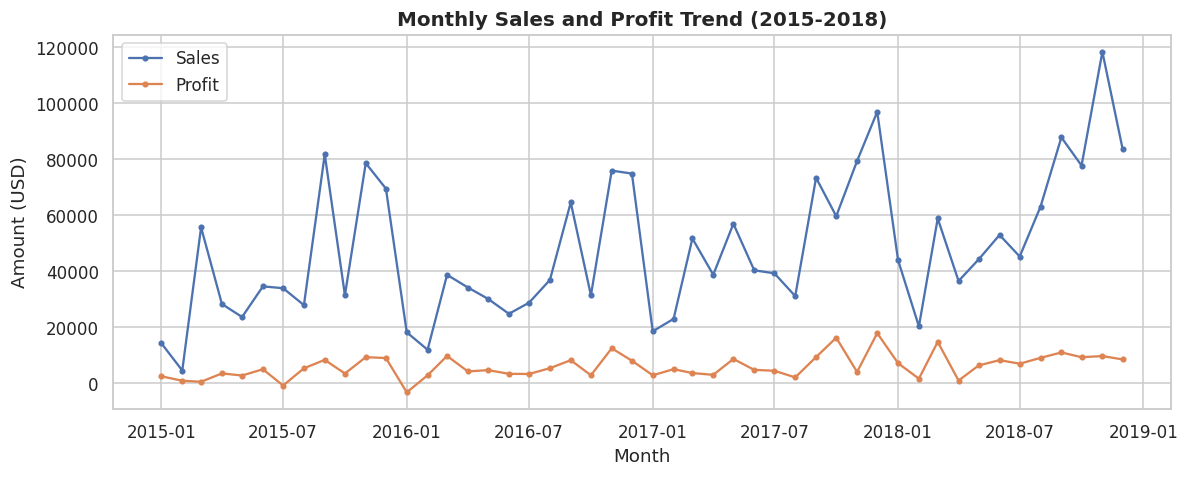

In [10]:
yr = df.groupby('YearMonth').agg(Sales=('Sales','sum'),Profit=('Profit','sum'))
fig,ax = plt.subplots(figsize=(11,4.5))
ax.plot(yr.index, yr.Sales, marker='o', ms=3, label='Sales'); ax.plot(yr.index, yr.Profit, marker='o', ms=3, label='Profit')
ax.set(title='Monthly Sales and Profit Trend (2015-2018)', xlabel='Month', ylabel='Amount (USD)'); ax.legend()
plt.tight_layout(); plt.savefig('charts/01_monthly_trend.png'); plt.show()

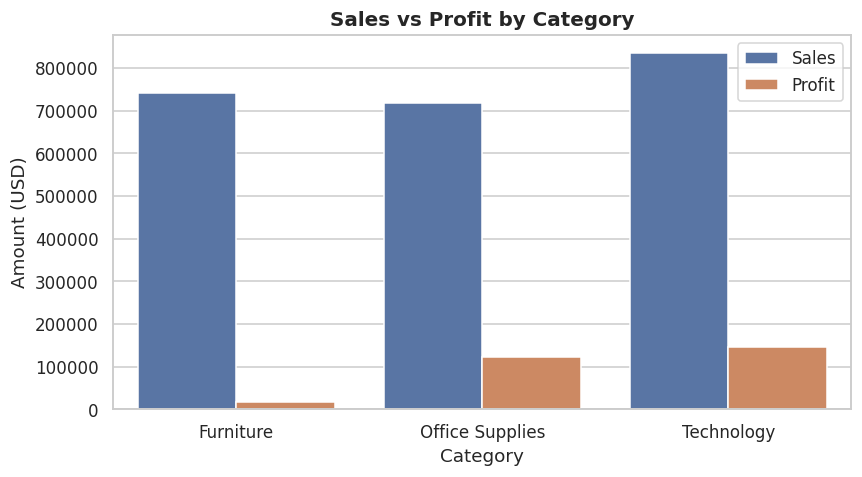

In [11]:
cat = df.groupby('Category')[['Sales','Profit']].sum().reset_index().melt(id_vars='Category')
fig,ax = plt.subplots(figsize=(8,4.5)); sns.barplot(data=cat,x='Category',y='value',hue='variable',ax=ax)
ax.set(title='Sales vs Profit by Category', xlabel='Category', ylabel='Amount (USD)'); ax.legend(title='')
plt.tight_layout(); plt.savefig('charts/02_category.png'); plt.show()

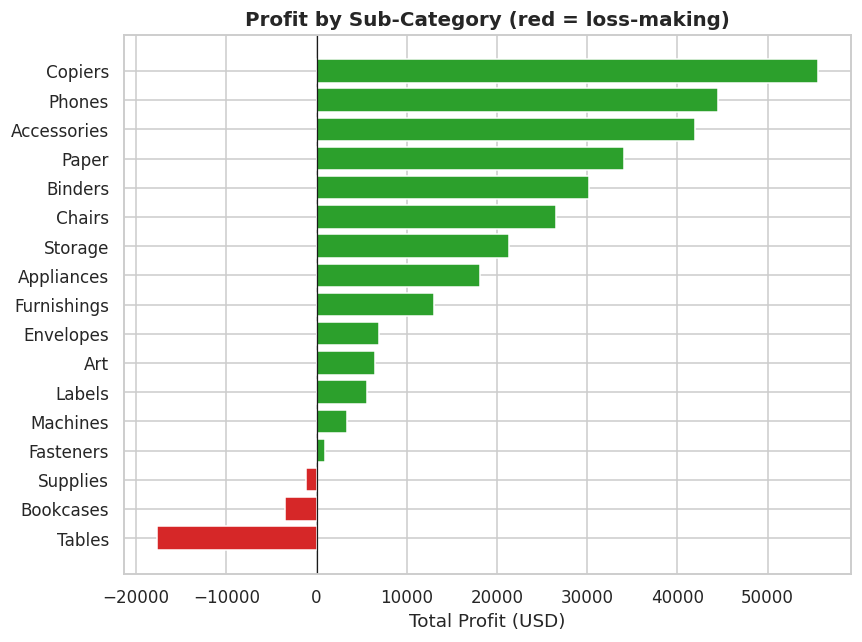

In [12]:
sub = df.groupby('Sub-Category').Profit.sum().sort_values()
fig,ax = plt.subplots(figsize=(8,6)); ax.barh(sub.index, sub.values, color=['#d62728' if v<0 else '#2ca02c' for v in sub.values])
ax.axvline(0,color='k',lw=.8); ax.set(title='Profit by Sub-Category (red = loss-making)', xlabel='Total Profit (USD)', ylabel='')
plt.tight_layout(); plt.savefig('charts/03_subcategory_profit.png'); plt.show()

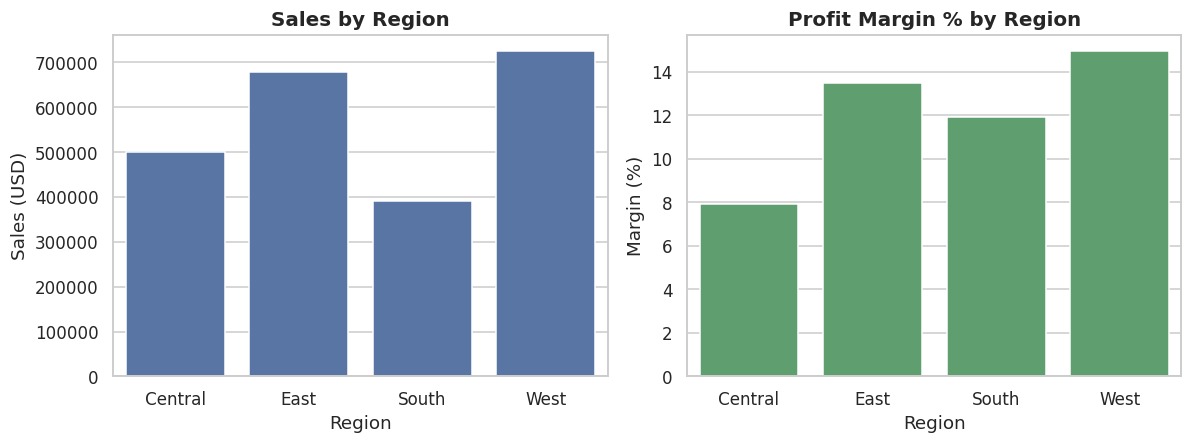

In [13]:
reg = df.groupby('Region').agg(Sales=('Sales','sum'),Profit=('Profit','sum')); reg['Margin %']=reg.Profit/reg.Sales*100
fig,ax = plt.subplots(1,2,figsize=(11,4.2))
sns.barplot(x=reg.index,y=reg.Sales,ax=ax[0],color='#4c72b0'); ax[0].set(title='Sales by Region',xlabel='Region',ylabel='Sales (USD)')
sns.barplot(x=reg.index,y=reg['Margin %'],ax=ax[1],color='#55a868'); ax[1].set(title='Profit Margin % by Region',xlabel='Region',ylabel='Margin (%)')
plt.tight_layout(); plt.savefig('charts/04_region.png'); plt.show()

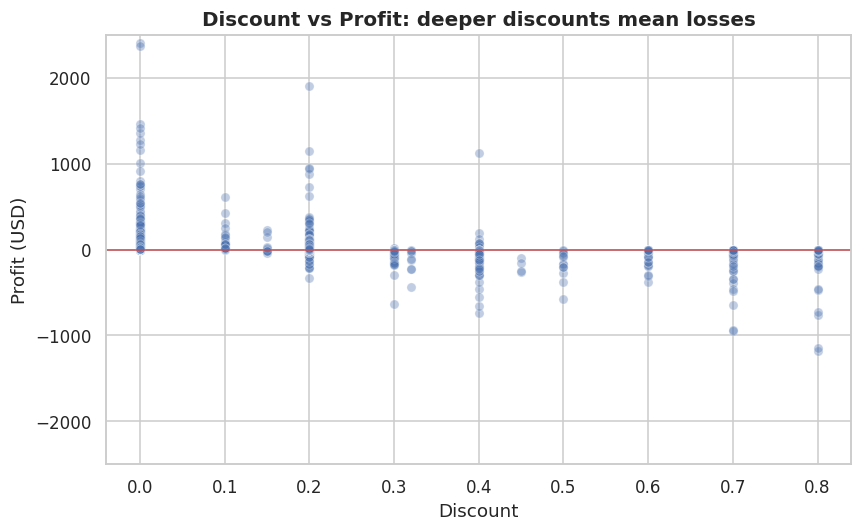

In [14]:
fig,ax = plt.subplots(figsize=(8,5))
s = df.sample(3000, random_state=1); sns.scatterplot(data=s,x='Discount',y='Profit',alpha=.35,ax=ax)
ax.axhline(0,color='r',lw=1); ax.set(title='Discount vs Profit: deeper discounts mean losses', xlabel='Discount', ylabel='Profit (USD)'); ax.set_ylim(-2500,2500)
plt.tight_layout(); plt.savefig('charts/05_discount_profit.png'); plt.show()

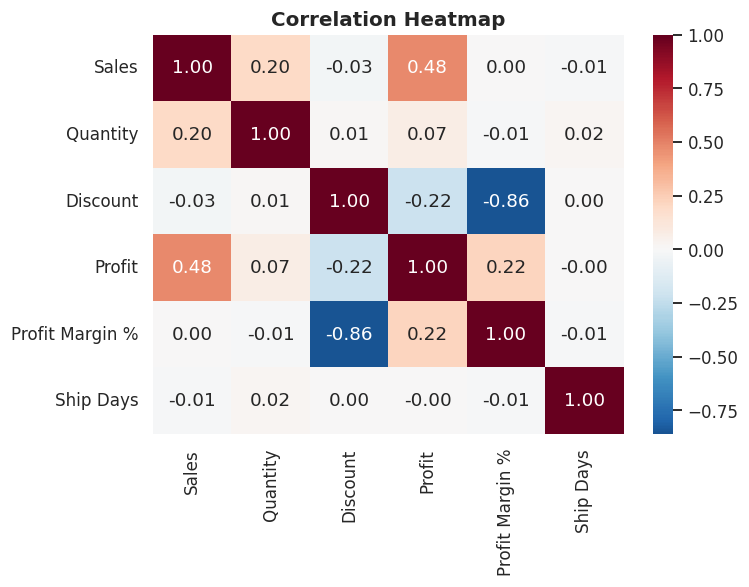

In [15]:
fig,ax = plt.subplots(figsize=(7,5.5)); sns.heatmap(corr,annot=True,cmap='RdBu_r',center=0,fmt='.2f',ax=ax)
ax.set_title('Correlation Heatmap'); plt.tight_layout(); plt.savefig('charts/06_correlation.png'); plt.show()

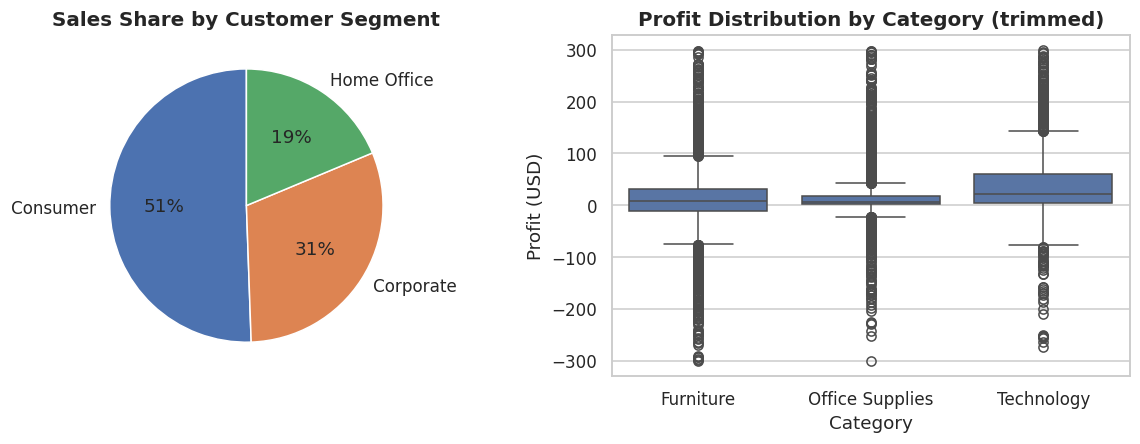

In [16]:
fig,ax = plt.subplots(1,2,figsize=(11,4.2))
seg = df.groupby('Segment').Sales.sum(); ax[0].pie(seg,labels=seg.index,autopct='%1.0f%%',startangle=90,colors=sns.color_palette('deep')); ax[0].set_title('Sales Share by Customer Segment')
sns.boxplot(data=df[df.Profit.between(-300,300)],x='Category',y='Profit',ax=ax[1]); ax[1].set(title='Profit Distribution by Category (trimmed)',xlabel='Category',ylabel='Profit (USD)')
plt.tight_layout(); plt.savefig('charts/07_segment_box.png'); plt.show()

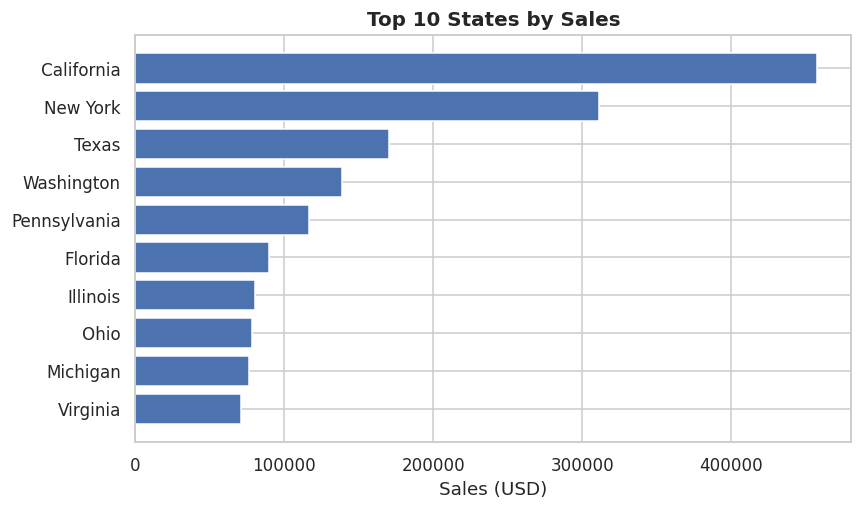

In [17]:
top = df.groupby('State').Sales.sum().nlargest(10).sort_values()
fig,ax = plt.subplots(figsize=(8,4.8)); ax.barh(top.index, top.values, color='#4c72b0')
ax.set(title='Top 10 States by Sales', xlabel='Sales (USD)', ylabel='')
plt.tight_layout(); plt.savefig('charts/08_top_states.png'); plt.show()